# English-to-French translation with global attention

A PyTorch GRU encoder-decoder that generates French translations one token at a time. The experiment examines training behavior, greedy decoding errors, and the relationship between attention weights and word order.

The recorded 20-epoch run reduced validation cross-entropy from **4.60 to 2.76**. Translation examples and attention plots use a **separate reference checkpoint**, not the weights from that run.

Implementation and analysis: Houssam Fidani. See the [README](README.md) for a short overview and setup instructions.


## 1. Experiment and recorded results

The data contains preprocessed English/French sentence pairs from Tatoeba via ManyThings. The distributed split has 136,521 training pairs and 34,130 evaluation pairs. The latter split controls early stopping, so it is treated as **validation**, not an untouched test set.

| Setting | Value |
|---|---|
| Encoder / decoder | One unidirectional GRU each |
| Embedding dimensions | 40 / 40 |
| GRU hidden dimensions | 30 / 30 |
| Attention hidden dimension | 20 |
| Optimizer | Adam, learning rate 0.001 |
| Batch size / epochs | 64 / 20 |
| Decoding | Greedy, maximum 30 output tokens |

The chart below reads the original recorded epoch summaries. These are rounded log values; rerunning training produces a new experiment.


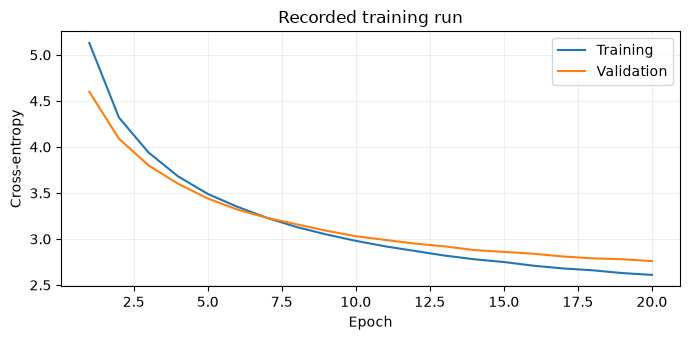

In [ ]:
from pathlib import Path
import json
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
if (PROJECT_DIR / 'attention-based-translation').is_dir():
    PROJECT_DIR = PROJECT_DIR / 'attention-based-translation'

recorded_history = json.loads((PROJECT_DIR / 'results/training-history.json').read_text())
fig, ax = plt.subplots(figsize=(7, 3.5))
for key, label in [('training_loss', 'Training'), ('validation_loss', 'Validation')]:
    ax.plot([row['epoch'] for row in recorded_history],
            [row[key] for row in recorded_history], label=label)
ax.set(xlabel='Epoch', ylabel='Cross-entropy', title='Recorded training run')
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 2. Environment and data

Install `requirements.txt` in the notebook's Python environment. The default run downloads the data and reference weights and explores their predictions. Set `RUN_TRAINING = True` to train a new model. The original training took roughly 45 minutes on its GPU runtime; CPU training can take substantially longer.

IDs 0, 1, 2, and 3 represent padding, unknown words, start-of-sequence, and end-of-sequence. Other IDs come from vocabularies built on the training split.


In [ ]:
import random
import urllib.request
import zipfile
import numpy as np
import nltk
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils import data
from torch.nn.utils.rnn import pad_sequence
from nltk import word_tokenize
from tqdm.auto import tqdm

RUN_TRAINING = False
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)


In [ ]:
DATA_URL = 'https://nuage.lix.polytechnique.fr/public.php/dav/files/FLttXTmeFSDNx7H'
REFERENCE_URL = 'https://nuage.lix.polytechnique.fr/public.php/dav/files/6btZHdtYnyAAH3x'
DATA_DIR = PROJECT_DIR / 'data'
CHECKPOINT_DIR = PROJECT_DIR / 'checkpoints'
CHECKPOINT_DIR.mkdir(exist_ok=True)
REFERENCE_CHECKPOINT = CHECKPOINT_DIR / 'reference_translator.pt'
TRAINED_CHECKPOINT = CHECKPOINT_DIR / 'trained_translator.pt'

if not (DATA_DIR / 'vocab_source.json').exists():
    archive_path = PROJECT_DIR / 'data.zip'
    urllib.request.urlretrieve(DATA_URL, archive_path)
    with zipfile.ZipFile(archive_path) as archive:
        for entry in archive.infolist():
            target = (PROJECT_DIR / entry.filename).resolve()
            if not target.is_relative_to(PROJECT_DIR.resolve()):
                raise ValueError('Unexpected archive path')
        archive.extractall(PROJECT_DIR)
    archive_path.unlink()
if not REFERENCE_CHECKPOINT.exists():
    urllib.request.urlretrieve(REFERENCE_URL, REFERENCE_CHECKPOINT)
path_to_data = str(DATA_DIR) + '/'


## 3. Model

The encoder maps source tokens to a sequence of hidden states. At each decoder step, concatenation-based global attention scores the current decoder state against all source states. The normalized scores form a weighted context vector, which is combined with the decoder GRU output to predict the next token.

The implementation follows the global-attention formulation in [Luong et al. (2015)](https://arxiv.org/abs/1508.04025), with single-layer GRUs. The decoder feeds back its own predictions during both training and inference.


### Encoder


In [ ]:
class Encoder(nn.Module):
    '''
    to be passed the entire source sequence at once
    we use padding_idx in nn.Embedding so that the padding vector does not take gradient (always zero)
    https://pytorch.org/docs/stable/nn.html#gru
    '''
    def __init__(self, vocab_size, embedding_dim, hidden_dim, padding_idx):
        super(Encoder, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx)
        self.rnn = nn.GRU(embedding_dim, hidden_dim)

    def forward(self, input):
        word_vectors = self.embedding(input)
        hs,_ = self.rnn(word_vectors) # (seq,batch,feat)
        return hs


### Decoder


In [ ]:
class Decoder(nn.Module):
    '''to be used one timestep at a time
       see https://pytorch.org/docs/stable/nn.html#gru'''
    def __init__(self, vocab_size, embedding_dim, hidden_dim, padding_idx):
        super(Decoder, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx)
        self.rnn = nn.GRU(embedding_dim, hidden_dim)
        self.ff_concat = nn.Linear(2*hidden_dim,hidden_dim)
        self.predict = nn.Linear(hidden_dim, vocab_size)

    def forward(self, input, source_context, h):
        word_vector = self.embedding(input) # (1,batch) -> (1,batch,feat)
        h,_= self.rnn(word_vector, h) # (1,batch,feat)
        tilde_h = torch.tanh(self.ff_concat(torch.cat((source_context, h), dim=2))) # (1,batch,2*feat) -> (1,batch,feat)
        prediction = self.predict(tilde_h) # (1,batch,feat) -> (1,batch,vocab)

        return prediction, h


### Global attention


In [ ]:
class GlobalAttention(nn.Module):
    '''
    concat global attention a la Luong et al. 2015 (subsection 3.1)
    https://arxiv.org/pdf/1508.04025.pdf
    '''
    def __init__(self, hidden_dim, hidden_dim_s, hidden_dim_t):
        super(GlobalAttention, self).__init__()
        self.ff_concat = nn.Linear(hidden_dim_s+hidden_dim_t,hidden_dim)
        self.ff_score = nn.Linear(hidden_dim,1,bias=False)

    def forward(self,target_h,source_hs):
        target_h_rep = target_h.repeat(source_hs.size(0),1,1) # (1,batch,feat) -> (seq,batch,feat)
        concat_output = torch.tanh(self.ff_concat(torch.cat((target_h_rep, source_hs), dim=2))) # source_hs is (seq,batch,feat)
        scores = self.ff_score(concat_output) # (seq,batch,feat) -> (seq,batch,1)
        scores = scores.squeeze(dim=2) # Preserve the batch axis for single examples.
        norm_scores = torch.softmax(scores, dim=0) # attention weights
        source_hs_p = source_hs.permute((2,0,1)) # (seq,batch,feat) -> (feat,seq,batch)
        weighted_source_hs = norm_scores * source_hs_p # (seq,batch) * (feat,seq,batch)
        ct = torch.sum(weighted_source_hs.permute((1,2,0)),0,keepdim=True) # (feat,seq,batch) -> (seq,batch,feat) -> (1,batch,feat)
        return ct, norm_scores.squeeze(1)


### Translation model and training loop


In [ ]:
class Seq2SeqTranslator(nn.Module):
    '''GRU encoder-decoder with optional global attention.'''
    ARGS = ['vocab_s','source_language','vocab_t_inv','embedding_dim_s','embedding_dim_t',
     'hidden_dim_s','hidden_dim_t','hidden_dim_att','do_att','padding_token',
     'oov_token','sos_token','eos_token','max_size']
    def __init__(self, vocab_s, source_language, vocab_t_inv, embedding_dim_s, embedding_dim_t,
                 hidden_dim_s, hidden_dim_t, hidden_dim_att, do_att, padding_token,
                 oov_token, sos_token, eos_token, max_size):
        super(Seq2SeqTranslator, self).__init__()
        self.vocab_s = vocab_s
        self.source_language = source_language
        self.vocab_t_inv = vocab_t_inv
        self.embedding_dim_s = embedding_dim_s
        self.embedding_dim_t = embedding_dim_t
        self.hidden_dim_s = hidden_dim_s
        self.hidden_dim_t = hidden_dim_t
        self.hidden_dim_att = hidden_dim_att
        self.do_att = do_att
        self.padding_token = padding_token
        self.oov_token = oov_token
        self.sos_token = sos_token
        self.eos_token = eos_token
        self.max_size = max_size

        self.max_source_idx = max(list(vocab_s.values()))
        print('max source index',self.max_source_idx)
        print('source vocab size',len(vocab_s))

        self.max_target_idx = max([int(elt) for elt in list(vocab_t_inv.keys())])
        print('max target index',self.max_target_idx)
        print('target vocab size',len(vocab_t_inv))

        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        self.encoder = Encoder(self.max_source_idx+1,self.embedding_dim_s,self.hidden_dim_s,self.padding_token).to(self.device)
        self.decoder = Decoder(self.max_target_idx+1,self.embedding_dim_t,self.hidden_dim_t,self.padding_token).to(self.device)

        if self.do_att:
            self.att_mech = GlobalAttention(self.hidden_dim_att,self.hidden_dim_s,self.hidden_dim_t).to(self.device)

    def my_pad(self,my_list):
        '''my_list is a list of tuples of the form [(tensor_s_1,tensor_t_1),...,(tensor_s_batch,tensor_t_batch)]
        the <eos> token is appended to each sequence before padding
        https://pytorch.org/docs/stable/nn.html#torch.nn.utils.rnn.pad_sequence'''
        batch_source = pad_sequence([torch.cat((elt[0],torch.LongTensor([self.eos_token]))) for elt in my_list],batch_first=True,padding_value=self.padding_token)
        batch_target = pad_sequence([torch.cat((elt[1],torch.LongTensor([self.eos_token]))) for elt in my_list],batch_first=True,padding_value=self.padding_token)
        return batch_source,batch_target

    def forward(self,input,max_size,is_prod):

        if is_prod:
            input = input.unsqueeze(1) # (seq) -> (seq,1) 1D input <=> we receive just one sentence as input (predict/production mode)

        current_batch_size = input.size(1)

        # use the encoder
        source_hs = self.encoder(input)  # (seq,batch)/(seq,1) -> (seq,batch,feat)/(seq,1,feat)

        # Autoregressive decoding

        target_h = torch.zeros(size=(1,current_batch_size,self.hidden_dim_t)).to(self.device) # init (1,batch,feat)

        # Start every sequence with SOS.
        target_input = torch.LongTensor([self.sos_token]).repeat(current_batch_size).unsqueeze(0).to(self.device) # init (1,batch)

        pos = 0
        eos_counter = 0
        logits = []
        weights = []

        while True:

            if self.do_att:
                source_context = self.att_mech(target_h,source_hs) # (1,batch,feat)
                weights.append(source_context[1].tolist()) # attention weights
                source_context = source_context[0]
            else:
                source_context = source_hs[-1,:,:].unsqueeze(0) # (1,batch,feat) last hidden state of encoder

            # use the decoder
            prediction, target_h = self.decoder(target_input, source_context, target_h)

            logits.append(prediction) # (1,batch,vocab)

            # get the next input to pass the decoder
            target_input = prediction.argmax(dim=2)

            eos_counter += torch.sum(target_input==self.eos_token).item()

            pos += 1
            if pos>=max_size or (eos_counter == current_batch_size and is_prod):
                break

        to_return = torch.cat(logits,0) # logits is a list of tensors -> (seq,batch,vocab)

        if is_prod:
            to_return = to_return.squeeze(dim=1) # (seq,vocab)

        return to_return, weights

    def fit(self, trainingDataset, validationDataset, lr, batch_size, n_epochs, patience):

        parameters = [p for p in self.parameters() if p.requires_grad]

        optimizer = optim.Adam(parameters, lr=lr)

        criterion = torch.nn.CrossEntropyLoss(ignore_index=self.padding_token)

        # Pad each batch to its longest sequence.
        train_loader = data.DataLoader(trainingDataset, batch_size=batch_size,
                                       shuffle=True, collate_fn=self.my_pad) # returns (batch,seq)

        validation_loader = data.DataLoader(validationDataset, batch_size=512,
                                      collate_fn=self.my_pad)

        tdqm_dict_keys = ['loss', 'validation loss']
        tdqm_dict = dict(zip(tdqm_dict_keys,[0.0,0.0]))

        patience_counter = 1
        patience_loss = 99999

        for epoch in range(n_epochs):

            with tqdm(total=len(train_loader),unit_scale=True,postfix={'loss':0.0,'validation loss':0.0},
                      desc="Epoch : %i/%i" % (epoch, n_epochs-1),ncols=100) as pbar:
                for loader_idx, loader in enumerate([train_loader, validation_loader]):
                    total_loss = 0
                    # Update weights on training batches only.
                    if loader_idx == 0:
                        self.train()
                    else:
                        self.eval()
                    for i, (batch_source,batch_target) in enumerate(loader):
                        batch_source = batch_source.transpose(1,0).to(self.device) # RNN needs (seq,batch,feat) but loader returns (batch,seq)
                        batch_target = batch_target.transpose(1,0).to(self.device) # (seq,batch)

                        # Single-sequence inputs use inference decoding limits.
                        is_prod = len(batch_source.shape)==1 # if False, 2D input (seq,batch), i.e., training or validation

                        if is_prod:
                            max_size = self.max_size
                            self.eval()
                        else:
                            max_size = batch_target.size(0) # no need to continue generating after we've exceeded the length of the longest ground truth sequence

                        unnormalized_logits = self.forward(batch_source,max_size,is_prod)[0]

                        sentence_loss = criterion(unnormalized_logits.flatten(end_dim=1),batch_target.flatten())

                        total_loss += sentence_loss.item()

                        tdqm_dict[tdqm_dict_keys[loader_idx]] = total_loss/(i+1)

                        pbar.set_postfix(tdqm_dict)

                        if loader_idx == 0:
                            optimizer.zero_grad() # flush gradient attributes
                            sentence_loss.backward() # compute gradients
                            optimizer.step() # update
                            pbar.update(1)

            if total_loss > patience_loss:
                patience_counter += 1
            else:
                patience_loss = total_loss
                patience_counter = 1 # reset

            if patience_counter>patience:
                break

    def sourceNl_to_ints(self,source_nl):
        '''converts natural language source sentence into source integers'''
        source_nl_clean = source_nl.lower().replace("'",' ').replace('-',' ')
        source_nl_clean_tok = word_tokenize(source_nl_clean,self.source_language)
        source_ints = [int(self.vocab_s[elt]) if elt in self.vocab_s else \
                       self.oov_token for elt in source_nl_clean_tok]

        source_ints = torch.LongTensor(source_ints).to(self.device)
        return source_ints

    def targetInts_to_nl(self,target_ints):
        '''converts integer target sentence into target natural language'''
        return ['<PAD>' if elt==self.padding_token else '<OOV>' if elt==self.oov_token \
                else '<EOS>' if elt==self.eos_token else '<SOS>' if elt==self.sos_token\
                else self.vocab_t_inv[elt] for elt in target_ints]

    def predict(self,source_nl):
        source_ints = self.sourceNl_to_ints(source_nl)
        source_ints = torch.cat((source_ints, source_ints.new_tensor([self.eos_token])))
        logits = self.forward(source_ints,self.max_size,True) # (seq) -> (<=max_size,vocab)
        target_ints = logits[0].argmax(-1).reshape(-1) # (<=max_size,1) -> (<=max_size)
        target_nl = self.targetInts_to_nl(target_ints.tolist())
        return ' '.join(target_nl), logits[1]

    def save(self,path_to_file):
        attrs = {attr:getattr(self,attr) for attr in self.ARGS}
        attrs['state_dict'] = self.state_dict()
        torch.save(attrs,path_to_file)

    @classmethod
    def load(cls,path_to_file):
        attrs = torch.load(path_to_file, map_location='cpu', weights_only=True)
        state_dict = attrs.pop('state_dict')
        new = cls(**attrs)
        new.load_state_dict(state_dict)
        return new


## 4. Train a new checkpoint

Training is optional. The saved chart above remains a record of the original experiment; it is not overwritten by this run. The implementation does not mask padded encoder positions in attention and uses greedy feedback rather than teacher forcing. These are limitations of this baseline.


In [ ]:
class Dataset(data.Dataset):
  def __init__(self, pairs):
        self.pairs = pairs

  def __len__(self):
        return len(self.pairs) # total nb of observations

  def __getitem__(self, idx):
        source, target = self.pairs[idx] # one observation
        return torch.LongTensor(source), torch.LongTensor(target)

def load_pairs(train_or_test):
    with open(path_to_data + 'pairs_' + train_or_test + '_ints.txt', 'r', encoding='utf-8') as file:
        pairs_tmp = file.read().splitlines()
    pairs_tmp = [elt.split('\t') for elt in pairs_tmp]
    pairs_tmp = [[[int(eltt) for eltt in elt[0].split()],[int(eltt) for eltt in \
                  elt[1].split()]] for elt in pairs_tmp]
    return pairs_tmp


In [ ]:
if RUN_TRAINING:
    do_att = True
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    pairs_train = load_pairs('train')
    pairs_validation = load_pairs('test')  # Archive filename; used for validation.
    
    with open(path_to_data + 'vocab_source.json','r') as file:
        vocab_source = json.load(file) # word -> index
    
    with open(path_to_data + 'vocab_target.json','r') as file:
        vocab_target = json.load(file) # word -> index
    
    vocab_target_inv = {v:k for k,v in vocab_target.items()} # index -> word
    print('data loaded')
    training_set = Dataset(pairs_train)
    validation_set = Dataset(pairs_validation)
    print('data prepared')
    print('Global attention:', do_att)
    
    model = Seq2SeqTranslator(vocab_s=vocab_source,
                          source_language='english',
                          vocab_t_inv=vocab_target_inv,
                          embedding_dim_s=40,
                          embedding_dim_t=40,
                          hidden_dim_s=30,
                          hidden_dim_t=30,
                          hidden_dim_att=20,
                          do_att=do_att,
                          padding_token=0,
                          oov_token=1,
                          sos_token=2,
                          eos_token=3,
                          max_size=30).to(device) # max size of generated sentence in prediction mode
    
    model.fit(training_set,validation_set,lr=0.001,batch_size=64,n_epochs=20,patience=2)
    model.save(TRAINED_CHECKPOINT)
else:
    print("Training skipped. Set RUN_TRAINING = True to create a new checkpoint.")


## 5. Inspect the reference checkpoint

The following predictions and attention plots come from the separately distributed reference weights. They illustrate model behavior and are not an evaluation of the 20-epoch training run. To inspect your own trained model, change `INFERENCE_CHECKPOINT` below to `TRAINED_CHECKPOINT` after training.


In [ ]:
INFERENCE_CHECKPOINT = REFERENCE_CHECKPOINT
model = Seq2SeqTranslator.load(INFERENCE_CHECKPOINT)
model.eval()
to_test = ['I am a student.',
            'I have a red car.',  # inversion captured
            'I love playing video games.',
            'This river is full of fish.', # plein vs pleine (accord)
            'The fridge is full of food.',
            'The cat fell asleep on the mat.',
            'my brother likes pizza.', # pizza is translated to 'la pizza'
            'I did not mean to hurt you', # translation of mean in context
            'She is so mean',
            'Help me pick out a tie to go with this suit!', # right translation
            'The kids were playing hide and seek',
            'The cat fell asleep in front of the fireplace']

for elt in to_test:
    print('= = = = = \n','%s -> %s' % (elt, model.predict(elt)[0]))


max source index 5281
source vocab size 5278
max target index 7459
target vocab size 7456
= = = = = 
 I am a student. -> je suis étudiant . <EOS>
= = = = = 
 I have a red car. -> j ai une voiture rouge . <EOS>
= = = = = 
 I love playing video games. -> j adore jouer à jeux jeux jeux vidéo . <EOS>
= = = = = 
 This river is full of fish. -> cette rivière est pleine de poisson . <EOS>
= = = = = 
 The fridge is full of food. -> le frigo est plein de nourriture . <EOS>
= = = = = 
 The cat fell asleep on the mat. -> le chat s est endormi sur le tapis . <EOS>
= = = = = 
 my brother likes pizza. -> mon frère aime la pizza . <EOS>
= = = = = 
 I did not mean to hurt you -> je n ai pas voulu intention de blesser blesser de faire ? <EOS>
= = = = = 
 She is so mean -> elle est tellement méchant de dire <EOS>
= = = = = 
 Help me pick out a tie to go with this suit! -> aidez moi à chercher une cravate pour aller avec ceci ! ! <EOS>
= = = = = 
 The kids were playing hide and seek -> les enfants jouent

### Repetition and missing meaning

| Source | Reference-model output excerpt | Observation |
|---|---|---|
| I love playing video games. | j adore jouer à jeux jeux jeux vidéo | Repeated word |
| The kids were playing hide and seek | les enfants jouent cache cache cache cache coudre coudre | Repetition and unrelated content |
| The cat fell asleep in front of the fireplace | le chat s est en du la de ? | Missing action and location |

Greedy decoding chooses the next token with the highest probability, without comparing complete translations. An early mistake can therefore affect the remaining sequence. Beam search would retain multiple candidates, while coverage and input feeding could help address repeated or omitted content. Those alternatives have **not** been implemented or compared here.


### Attention alignments


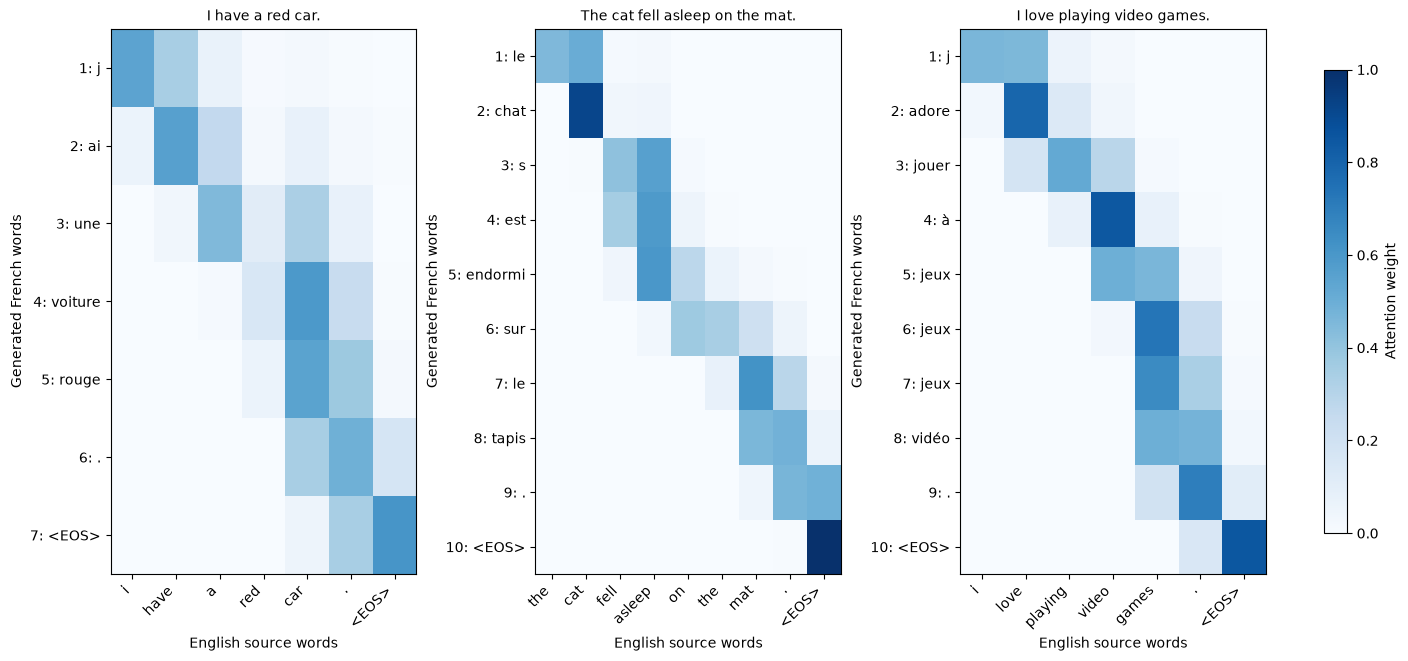

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

model.eval()
source_inv = {int(index): word for word, index in model.vocab_s.items()}


@torch.inference_mode()
def alignment_data(sentence):
    source_ids = model.sourceNl_to_ints(sentence)
    source_words = [source_inv.get(int(index), '<OOV>') for index in source_ids] + ['<EOS>']
    translation, weights = model.predict(sentence)
    target_words = translation.split()
    attention = np.asarray(weights)
    assert attention.shape == (len(target_words), len(source_words))
    assert np.allclose(attention.sum(axis=1), 1, atol=1e-6)
    return {'source_words': source_words, 'target_words': target_words, 'attention': attention}


examples = ['I have a red car.', 'The cat fell asleep on the mat.', 'I love playing video games.']
alignments = [alignment_data(sentence) for sentence in examples]
fig, axes = plt.subplots(1, 3, figsize=(14, 6.5), layout='constrained')
for ax, sentence, result in zip(axes, examples, alignments):
    image = ax.imshow(result['attention'], cmap='Blues', vmin=0, vmax=1,
                      aspect='auto', interpolation='nearest', origin='upper')
    ax.set_xticks(range(len(result['source_words'])), labels=result['source_words'], rotation=45, ha='right')
    target_labels = [f'{i + 1}: {word}' for i, word in enumerate(result['target_words'])]
    ax.set_yticks(range(len(target_labels)), labels=target_labels)
    ax.set_title(sentence, fontsize=10)
    ax.set_xlabel('English source words')
    ax.set_ylabel('Generated French words')
fig.colorbar(image, ax=axes, label='Attention weight', shrink=0.85)
plt.show()


Rows are generated French tokens and columns are source positions, including EOS. Each attention row sums to one.

- `red car` becomes `voiture rouge`. The output order is correct, but the weights do not form a simple word-to-word reversal: the encoder state for `car` also contains context from `red`.
- `chat` places most of its attention on `cat`; `s est endormi` draws on `fell asleep`.
- Repeated `jeux` tokens keep attending to `games`, consistent with the repetition in the output.

Attention weights describe this model's internal alignment; they are not proof of a causal explanation.


### Context-sensitive representations

The reference model translates `mean` differently in `I did not mean to hurt you` and `She is so mean`: it produces words related to intention in the first case and `méchant` in the second. Both translations still contain errors. A shared token embedding can lead to different contextual states because the GRU processes different preceding words.

## 6. Scope and next experiments

The saved results show decreasing validation loss and qualitative attention behavior. They do not establish a BLEU score or a competitive translation benchmark. A stronger evaluation would add an untouched test split, padding masks, and controlled comparisons of greedy decoding, beam search, and coverage.
